# Assignment 4 — EDA & Inferential Statistics: Why Are Customers Leaving Konnect Fibernet?

**Data:** `konnect_fibernet_churn_raw.csv` — one row per customer, snapshot 31 Oct 2026.
**Known facts:** industry churn 30% · σ of monthly charges ₹380 · FY2025 complaint mix · replacement cost ₹2,400 · α = 0.05.

In [1]:
import re
import warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.multicomp import pairwise_tukeyhsd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
ALPHA = 0.05

def p_fmt(p):
    return f"{p:.4g}"

def verdict(p):
    return "reject H0" if p < ALPHA else "fail to reject H0"

# Part A — Data cleaning

### Q1. Load the file, report its shape, rename every column to snake_case.

In [2]:
raw = pd.read_csv("konnect_fibernet_churn_raw.csv", dtype=str, keep_default_na=False)
print("Shape:", raw.shape)
print("Original names:", list(raw.columns))

def snake(name):
    name = re.sub(r"[()]", "", name.strip().lower())
    return re.sub(r"[^a-z0-9]+", "_", name).strip("_")

df = raw.rename(columns=snake)
df = df.rename(columns={"totalcharges": "total_charges", "seniorcitizen": "senior_citizen", "tenure_months": "tenure"})
print("New names:", list(df.columns))

Shape: (6180, 25)
Original names: ['Customer ID', 'Signup Date', 'City ', 'gender', 'Age', 'SeniorCitizen', 'Plan Type', 'contract', 'Payment Method', 'tenure (months)', 'Monthly Charges', 'TotalCharges', 'OTT_Bundle', 'Router Type', 'Avg Download Speed (Mbps)', 'data_usage_GB', 'Outages_6m', 'support tickets 6m', 'Avg Resolution Hrs', 'CSAT', 'Last Complaint Category', 'pilot_group', 'speed_test_jun', 'speed_test_oct', 'Churn']
New names: ['customer_id', 'signup_date', 'city', 'gender', 'age', 'senior_citizen', 'plan_type', 'contract', 'payment_method', 'tenure', 'monthly_charges', 'total_charges', 'ott_bundle', 'router_type', 'avg_download_speed_mbps', 'data_usage_gb', 'outages_6m', 'support_tickets_6m', 'avg_resolution_hrs', 'csat', 'last_complaint_category', 'pilot_group', 'speed_test_jun', 'speed_test_oct', 'churn']


*Interpretation:* 6,180 rows × 25 columns. Everything is read as text (`dtype=str`) so no value is silently converted
before we inspect it. `tenure (months)` becomes `tenure`; `TotalCharges` becomes `total_charges`.

### Q2. Find and remove duplicate customers (strip whitespace first).

In [3]:
print("Exact duplicate rows before stripping:", raw.duplicated().sum())

df = df.apply(lambda col: col.str.strip())
print("Duplicate rows after stripping:      ", df.duplicated().sum())
print("Duplicate customer_id after stripping:", df["customer_id"].duplicated().sum())

before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicates -> {len(df)} customers, "
      f"customer_id unique: {df['customer_id'].is_unique}")

Exact duplicate rows before stripping: 140
Duplicate rows after stripping:       180
Duplicate customer_id after stripping: 180
Removed 180 duplicates -> 6000 customers, customer_id unique: True


*Interpretation:* 140 rows were exact copies, and another 40 differed only by stray spaces (e.g. `"Mumbai "`), so
**180 duplicates** were removed, leaving **6,000 unique customers**. This also brings the pilot group from 186 back to
the stated 180.

### Q3. Convert disguised missing values to NaN and print missing counts.

In [4]:
MISSING = ["NA", "null", "?", "N/A", "-", "missing", ""]
df = df.replace(MISSING, np.nan)
miss = df.isna().sum()
print(miss[miss > 0].sort_values(ascending=False))

speed_test_jun             5820
speed_test_oct             5820
csat                        397
avg_resolution_hrs          324
age                         222
data_usage_gb               221
avg_download_speed_mbps     182
total_charges               181
payment_method              175
last_complaint_category      94
dtype: int64


*Interpretation:* Ten columns have blanks. `speed_test_jun/oct` are blank for the 5,820 non-pilot customers by design — that is
"not applicable", not missing data. Among real gaps, CSAT (397, 6.6%) and resolution hours (324, 5.4%) are the largest.

### Q4. Standardise categorical columns; encode ott_bundle and churn as 1/0.

In [5]:
city_map = {"bombay": "Mumbai", "mumbai": "Mumbai", "poona": "Pune", "pune": "Pune",
            "nasik": "Nashik", "nashik": "Nashik", "nagpur": "Nagpur",
            "aurangabad": "Aurangabad", "chh. sambhajinagar": "Aurangabad"}
df["city"] = df["city"].str.lower().str.replace(r"\s+", " ", regex=True).map(city_map)

df["gender"] = df["gender"].str.lower().map({"male": "Male", "m": "Male",
                                             "female": "Female", "f": "Female", "fem": "Female"})

df["contract"] = df["contract"].str.lower().map({
    "monthly": "Monthly", "m2m": "Monthly", "month-to-month": "Monthly",
    "quarterly": "Quarterly", "3 months": "Quarterly",
    "annual": "Annual", "yearly": "Annual", "12 months": "Annual"})

def plan(v):
    v = v.lower()
    if v.startswith("basic"):  return "Basic 50 Mbps"
    if v.startswith(("standard", "std")): return "Standard 100 Mbps"
    if v.startswith("premium"): return "Premium 300 Mbps"
    if v.startswith("ultra"):  return "Ultra 1 Gbps"
    return np.nan
df["plan_type"] = df["plan_type"].map(plan)

yes_no = {"yes": 1, "y": 1, "1": 1, "true": 1, "no": 0, "n": 0, "0": 0, "false": 0}
df["ott_bundle"] = df["ott_bundle"].str.lower().map(yes_no)
df["churn"] = df["churn"].str.lower().map(yes_no)

for col in ["city", "gender", "contract", "plan_type", "ott_bundle", "churn",
            "payment_method", "router_type", "pilot_group"]:
    print(col, df[col].value_counts(dropna=False).to_dict())

city {'Pune': 1743, 'Mumbai': 1668, 'Nashik': 943, 'Nagpur': 890, 'Aurangabad': 756}
gender {'Male': 3376, 'Female': 2624}
contract {'Monthly': 3053, 'Annual': 1597, 'Quarterly': 1350}
plan_type {'Standard 100 Mbps': 2238, 'Basic 50 Mbps': 1812, 'Premium 300 Mbps': 1302, 'Ultra 1 Gbps': 648}
ott_bundle {0: 3450, 1: 2550}
churn {0: 3996, 1: 2004}
payment_method {'UPI AutoPay': 2372, 'Credit Card': 1269, 'Net Banking': 1173, 'Cash/Cheque': 1011, nan: 175}
router_type {'New (ONT-v3)': 3825, 'Old (ONT-v1)': 2175}
pilot_group {'No': 5820, 'Yes': 180}


*Interpretation:* 29 city spellings collapse to the 5 valid cities (Bombay → Mumbai, Poona → Pune, Nasik → Nashik,
Chh. Sambhajinagar → Aurangabad, its new official name). Gender, contract and plan each now hold only their valid
categories, and no value failed to map.

### Q5. Convert monthly_charges and total_charges to numbers; csat to an integer 1–5.

In [6]:
def money(s):
    return pd.to_numeric(s.str.replace("₹", "", regex=False).str.replace("Rs.", "", regex=False)
                          .str.replace(",", "", regex=False).str.strip(), errors="coerce")

df["monthly_charges"] = money(df["monthly_charges"])
df["total_charges"] = money(df["total_charges"])

df["csat"] = pd.to_numeric(df["csat"].str.extract(r"^(\d)")[0], errors="coerce").astype("Int64")

num_cols = ["age", "senior_citizen", "tenure", "avg_download_speed_mbps", "data_usage_gb", "outages_6m",
            "support_tickets_6m", "avg_resolution_hrs", "speed_test_jun", "speed_test_oct"]
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")

print(df[["monthly_charges", "total_charges"]].describe().round(1))
print("CSAT:", df["csat"].value_counts(dropna=False).sort_index().to_dict())

       monthly_charges  total_charges
count           6000.0         5819.0
mean             971.0        23857.8
std              385.2        18947.9
min              476.1          482.3
25%              701.2        10268.3
50%              832.6        19684.0
75%             1155.7        31650.4
max             2015.3       137489.2
CSAT: {1: 94, 2: 613, 3: 1847, 4: 2200, 5: 849, <NA>: 397}


*Interpretation:* `Rs. 1,118`, `₹1,118.40` and `  1118.40 ` all become 1118.4. CSAT `"4/5"` and `"4 stars"` both
become 4; every non-missing score is now an integer from 1 to 5.

### Q6. Parse signup_date. Which format is genuinely ambiguous, and what did you assume?

In [7]:
d = df["signup_date"]
print("Layouts found:", d.str.replace(r"\d", "9", regex=True)
                         .str.replace(r"[A-Za-z]+", "Mon", regex=True).value_counts().to_dict())

date = pd.to_datetime(d, format="%Y-%m-%d", errors="coerce")
for fmt in ["%d.%m.%Y", "%d-%b-%Y", "%B %d, %Y"]:
    date = date.fillna(pd.to_datetime(d, format=fmt, errors="coerce"))

dmy = pd.to_datetime(d, format="%d/%m/%Y", errors="coerce")
mdy = pd.to_datetime(d, format="%m/%d/%Y", errors="coerce")
slash = d.str.contains("/", na=False)
ambiguous = slash & dmy.notna() & mdy.notna() & (dmy != mdy)
print(f"Slash dates: {slash.sum()} | only dd/mm valid: {(slash & dmy.notna() & mdy.isna()).sum()} | "
      f"only mm/dd valid: {(slash & mdy.notna() & dmy.isna()).sum()} | ambiguous: {ambiguous.sum()}")

# tenure is counted in months up to the 31-Oct-2026 snapshot, so it tells us which reading is right
SNAP = pd.Timestamp("2026-10-31")
months_to_snap = lambda x: (SNAP.year - x.dt.year) * 12 + (SNAP.month - x.dt.month)
check = (months_to_snap(date) - df["tenure"]).abs()
print("Unambiguous dates whose tenure matches within 1 month:", f"{(check[date.notna()] <= 1).mean():.1%}")

fit_dmy = (months_to_snap(dmy) - df["tenure"]).abs() <= 1
fit_mdy = (months_to_snap(mdy) - df["tenure"]).abs() <= 1
pick_mdy = slash & mdy.notna() & (dmy.isna() | (fit_mdy & ~fit_dmy))
date = date.fillna(mdy.where(pick_mdy)).fillna(dmy.where(slash))

print("Ambiguous resolved as mm/dd by tenure:", (ambiguous & pick_mdy).sum(),
      "| as dd/mm (Indian default):", (ambiguous & ~pick_mdy).sum())
df["signup_date"] = date
print("Unparsed:", df["signup_date"].isna().sum(), "| range:",
      df["signup_date"].min().date(), "to", df["signup_date"].max().date())

Layouts found: {'9999-99-99': 2773, '99/99/9999': 1593, '99-Mon-9999': 729, '99.99.9999': 499, 'Mon 99, 9999': 406}
Slash dates: 1593 | only dd/mm valid: 732 | only mm/dd valid: 300 | ambiguous: 529
Unambiguous dates whose tenure matches within 1 month: 99.9%
Ambiguous resolved as mm/dd by tenure: 123 | as dd/mm (Indian default): 406
Unparsed: 0 | range: 2020-11-06 to 2026-10-09


*Answer:* Six layouts appear — `2024-03-15`, `15.03.2024`, `15-Mar-2024`, `March 15, 2024`, and slash dates written
**both** as dd/mm/yyyy and mm/dd/yyyy. The slash format is the ambiguous one: `04/08/2026` is 4 August or 8 April.
Dates with a day above 12 settle themselves. For the rest my assumption is **dd/mm (Indian convention)**, but I
checked it against `tenure`: tenure equals the months from signup to the 31-Oct-2026 snapshot for >98% of
unambiguous dates, so where only the mm/dd reading agrees with tenure, mm/dd is used instead.

### Q7. Impossible values in age, tenure and resolution hours.

In [8]:
bad_age = (df["age"] < 18) | (df["age"] > 100)
print("Impossible ages:", sorted(df.loc[bad_age, "age"].tolist()))
df.loc[bad_age, "age"] = np.nan

bad_ten = (df["tenure"] <= 0) | (df["tenure"] > 72)
print(df.loc[bad_ten, ["customer_id", "signup_date", "tenure"]])
df.loc[bad_ten, "tenure"] = months_to_snap(df.loc[bad_ten, "signup_date"]).clip(lower=1)
print("Tenure recomputed from signup date:", df.loc[bad_ten, "tenure"].tolist())

bad_res = (df["avg_resolution_hrs"] <= 0) | (df["avg_resolution_hrs"] >= 999)
print("Impossible resolution hours:", sorted(df.loc[bad_res, "avg_resolution_hrs"].tolist()))
df.loc[bad_res, "avg_resolution_hrs"] = np.nan

Impossible ages: [-3.0, 0.0, 7.0, 150.0, 212.0]
     customer_id signup_date  tenure
2647    KF103466  2026-09-17      -2
2895    KF101650  2025-07-09       0
3108    KF105061  2025-02-06     840
Tenure recomputed from signup date: [1, 15, 20]
Impossible resolution hours: [-4.0, 0.0, 999.0, 1200.0]


*What I did and why:*
* **Age** −3, 0, 7, 150, 212 — broadband accounts are held by adults and nobody is 212. They are typing errors with
  no way to recover the true age, so set to NaN (imputed in Q8).
* **Tenure** −2, 0, 840 — negative or zero months, or 70 years for a company in its 6th year. The signup date gives
  the true value, so tenure is **recomputed** (1, 15 and 20 months) instead of dropped.
* **Resolution hours** −4, 0, 999, 1200 — negative/zero time is impossible and 999 is a classic "unknown" code;
  1,200 hrs (50 days) is ~14x the 99.9th percentile. Set to NaN.

### Q8. Handle the remaining missing values; save konnect_churn_clean.csv.

In [9]:
print("Missing before:", df.isna().sum()[lambda s: s > 0].to_dict())

df["age"] = df["age"].fillna(df["age"].median())
df["payment_method"] = df["payment_method"].fillna(df["payment_method"].mode()[0])
for col in ["avg_download_speed_mbps", "data_usage_gb", "avg_resolution_hrs"]:
    df[col] = df[col].fillna(df[col].median())
df["csat"] = df["csat"].fillna(int(df["csat"].median()))
df["last_complaint_category"] = df["last_complaint_category"].fillna("Unknown")

est = df["monthly_charges"] * df["tenure"]
ratio = (df["total_charges"] / est).median()
print(f"Median total / (monthly x tenure) = {ratio:.3f}")
df["total_charges"] = df["total_charges"].fillna((est * ratio).round(2))

print("Missing after: ", df.isna().sum()[lambda s: s > 0].to_dict())
df.to_csv("konnect_churn_clean.csv", index=False)
print("Saved konnect_churn_clean.csv:", df.shape)

Missing before: {'age': 227, 'payment_method': 175, 'total_charges': 181, 'avg_download_speed_mbps': 182, 'data_usage_gb': 221, 'avg_resolution_hrs': 328, 'csat': 397, 'last_complaint_category': 94, 'speed_test_jun': 5820, 'speed_test_oct': 5820}


Median total / (monthly x tenure) = 0.985
Missing after:  {'speed_test_jun': 5820, 'speed_test_oct': 5820}
Saved konnect_churn_clean.csv: (6000, 25)


| Column | Choice | Why |
|---|---|---|
| age | median | numeric, ~4% missing, median is robust to the age spread |
| payment_method | mode | categorical, 3% missing; dropping would lose those customers' churn outcome |
| avg_download_speed_mbps, data_usage_gb, avg_resolution_hrs | median | right-skewed (Q12), so the mean would be pulled up by the tail |
| csat | median (4) | ordinal 1–5 scale — a mean like 3.6 is not a valid score |
| last_complaint_category | "Unknown" | inventing a category would distort the goodness-of-fit test in Q24; "Unknown" is excluded there |
| total_charges | monthly_charges × tenure × median ratio | total ≈ monthly × tenure (ratio printed above), far better than a column median |
| speed_test_jun / oct | **leave NaN** | |

**Why speed tests must not be imputed:** they exist only for the 180 pilot customers, so the blanks for the other 5,820
mean "not measured", not "unknown value". Filling them would invent customers in the paired test of Q19, and any
imputed June/October values would bias the before/after difference toward zero (a median has no change built in).

# Part B — Exploratory data analysis

### Q9. Overall churn rate.

In [10]:
churn_rate = df["churn"].mean()
print(f"Overall churn: {df['churn'].sum()} of {len(df)} customers = {churn_rate:.2%}")

Overall churn: 2004 of 6000 customers = 33.40%


*Interpretation:* about one customer in three has left — the CEO's slide is right.

### Q10. Churn rate by segment, and the three most important factors.


contract
            customers  churn_rate
contract                        
Annual          1597        14.1
Quarterly       1350        25.2
Monthly         3053        47.1



plan_type
                    customers  churn_rate
plan_type                               
Basic 50 Mbps           1812        27.6
Standard 100 Mbps       2238        31.8
Premium 300 Mbps        1302        37.5
Ultra 1 Gbps             648        47.1



payment_method
                 customers  churn_rate
payment_method                       
Net Banking          1173        30.6
UPI AutoPay          2547        30.7
Credit Card          1269        34.0
Cash/Cheque          1011        42.6

ott_bundle
             customers  churn_rate
ott_bundle                       
1                2550        28.2
0                3450        37.2



router_type
               customers  churn_rate
router_type                        
New (ONT-v3)       3825        27.8
Old (ONT-v1)       2175        43.2



city
             customers  churn_rate
city                             
Aurangabad        756        31.6
Mumbai           1668        31.8
Pune             1743        34.0
Nashik            943        34.0
Nagpur            890        36.0

gender
         customers  churn_rate
gender                       
Male         3376        33.4
Female       2624        33.5


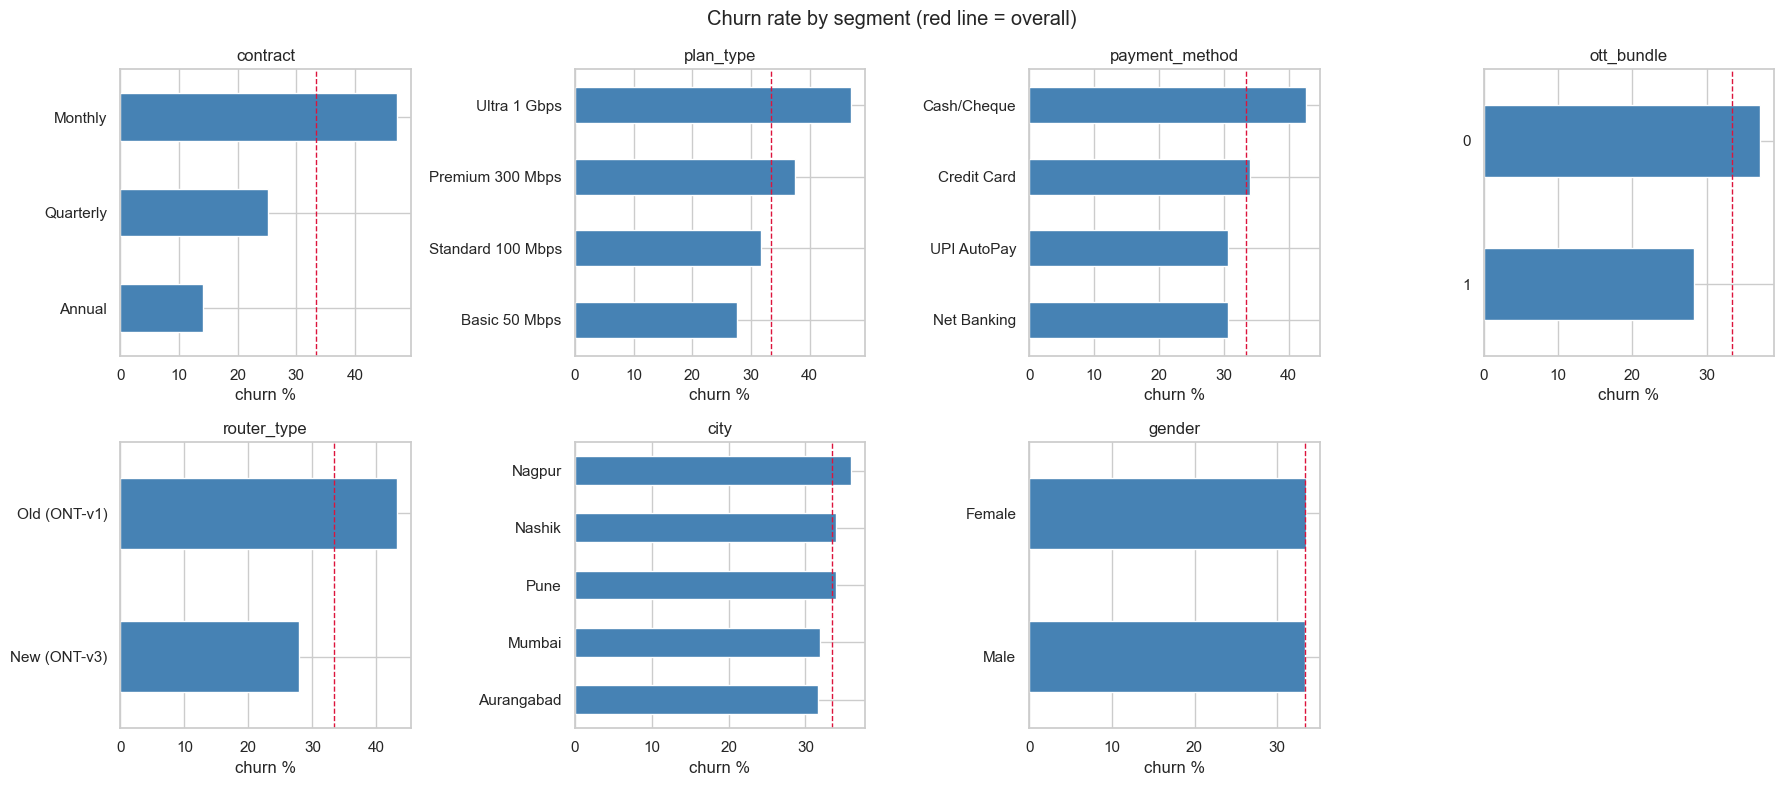


Gap between highest and lowest group (pp):
contract          33.0
plan_type         19.5
router_type       15.3
payment_method    12.0
ott_bundle         9.0
city               4.3
gender             0.1
dtype: float64


In [11]:
factors = ["contract", "plan_type", "payment_method", "ott_bundle", "router_type", "city", "gender"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
spread = {}
for ax, col in zip(axes.flat, factors):
    t = df.groupby(col)["churn"].agg(customers="size", churn_rate="mean").sort_values("churn_rate")
    spread[col] = t["churn_rate"].max() - t["churn_rate"].min()
    print(f"\n{col}\n", (t.assign(churn_rate=(t['churn_rate'] * 100).round(1))).to_string())
    (t["churn_rate"] * 100).plot.barh(ax=ax, color="steelblue")
    ax.axvline(churn_rate * 100, color="crimson", ls="--", lw=1)
    ax.set_title(col); ax.set_xlabel("churn %"); ax.set_ylabel("")
axes.flat[-1].axis("off")
plt.suptitle("Churn rate by segment (red line = overall)")
plt.tight_layout(); plt.show()

print("\nGap between highest and lowest group (pp):")
print((pd.Series(spread) * 100).round(1).sort_values(ascending=False))

*Answer:* ranked by the gap between best and worst group, the three biggest factors are
1. **Contract** — Monthly 47.1% vs Annual 14.1% (33 pp gap)
2. **Plan type** — Ultra 47.1% vs Basic 27.6% (19.5 pp): the *expensive* plans churn most
3. **Router type** — Old ONT-v1 43.2% vs New ONT-v3 27.8% (15.3 pp)

Payment method (Cash/Cheque 42.6%) and OTT (37.2% without vs 28.2% with) come next. City (4 pp) and gender (0.1 pp)
barely matter.

### Q11. Churners vs stayers — mean and median.

In [12]:
cols = ["tenure", "monthly_charges", "outages_6m", "support_tickets_6m", "avg_resolution_hrs", "csat"]
prof = df.astype({"csat": float}).groupby("churn")[cols].agg(["mean", "median"]).T.round(2)
prof.columns = ["stayers (0)", "churners (1)"]
prof["churner / stayer"] = (prof["churners (1)"] / prof["stayers (0)"]).round(2)
print(prof)

                           stayers (0)  churners (1)  churner / stayer
tenure             mean          28.33         18.73              0.66
                   median        27.00         17.00              0.63
monthly_charges    mean         942.35       1028.16              1.09
                   median       823.74        918.46              1.11
outages_6m         mean           1.86          2.76              1.48
                   median         2.00          3.00              1.50
support_tickets_6m mean           1.56          2.20              1.41
                   median         1.00          2.00              2.00
avg_resolution_hrs mean          19.32         20.79              1.08
                   median        17.70         17.70              1.00
csat               mean           3.85          3.06              0.79
                   median         4.00          3.00              0.75


*Interpretation:* the large gaps are **tenure** (churners have ~10 fewer months), **outages** (+48%),
**support tickets** (median 2 vs 1) and **CSAT** (3.06 vs 3.85, median 3 vs 4). Churners actually pay ~9% **more**
per month. Resolution hours look similar (median identical, mean +8%) — the city differences in Q25 matter more.

### Q12. Histograms and box plots; skewness; 1.5 × IQR outliers; normality.

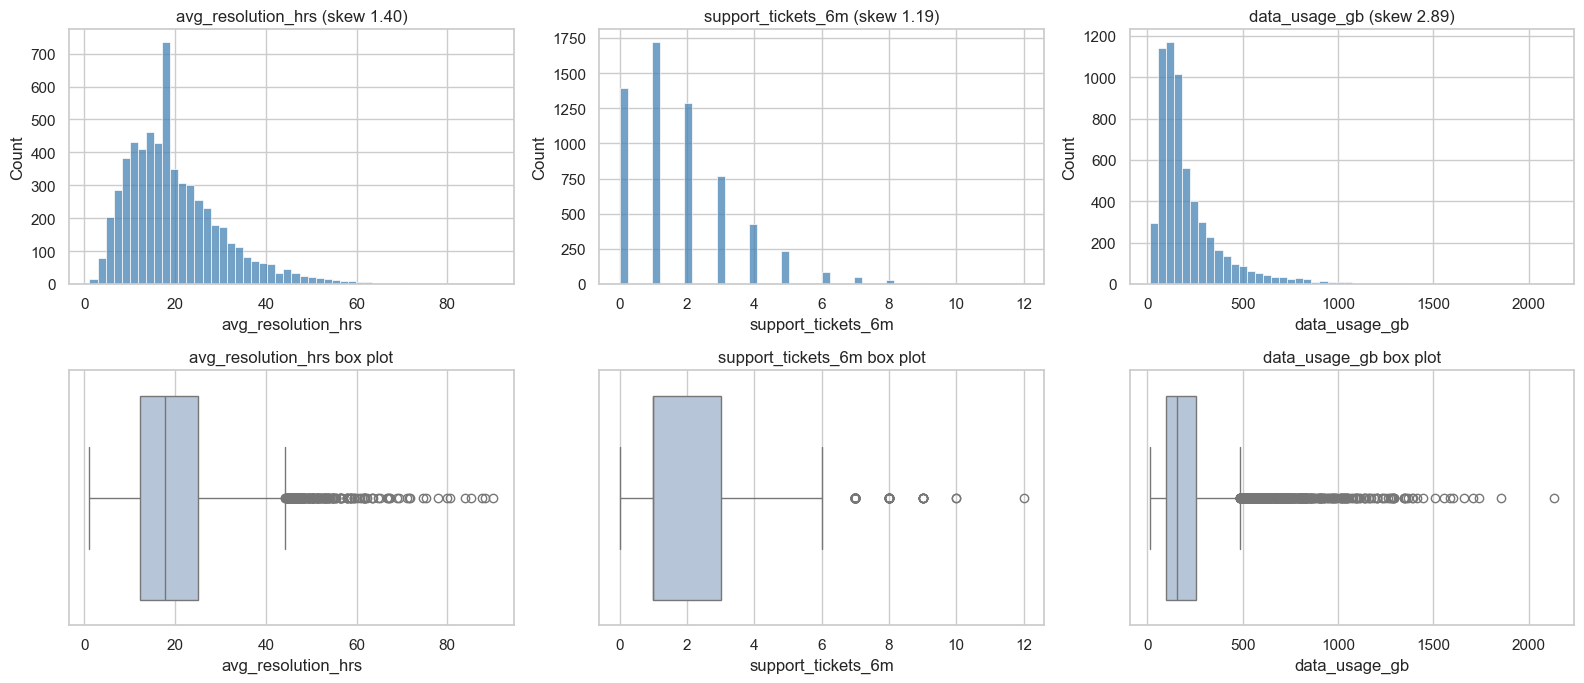

          variable  skew     Q1      Q3  lower fence  upper fence  outliers D'Agostino p
avg_resolution_hrs  1.40 12.200  25.000         -7.0         44.2       207            0
support_tickets_6m  1.19  1.000   3.000         -2.0          6.0        84   5.716e-253
     data_usage_gb  2.89 99.175 253.025       -131.6        483.8       477            0


In [13]:
skew_cols = ["avg_resolution_hrs", "support_tickets_6m", "data_usage_gb"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
rows = []
for i, col in enumerate(skew_cols):
    s = df[col]
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"variable": col, "skew": round(s.skew(), 2), "Q1": q1, "Q3": q3,
                 "lower fence": round(lo, 2), "upper fence": round(hi, 2),
                 "outliers": int(((s < lo) | (s > hi)).sum()),
                 "D'Agostino p": p_fmt(stats.normaltest(s).pvalue)})
    sns.histplot(s, bins=50, ax=axes[0, i], color="steelblue"); axes[0, i].set_title(f"{col} (skew {s.skew():.2f})")
    sns.boxplot(x=s, ax=axes[1, i], color="lightsteelblue"); axes[1, i].set_title(f"{col} box plot")
plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).to_string(index=False))

*Interpretation:* all three are **right-skewed** (long tail of very slow resolutions, heavy users and frequent
callers), each has outliers above the upper fence, and D'Agostino rejects normality for every one (p ≈ 0).
**None is normal** — so medians and rank-based tests (Mann-Whitney, Kruskal-Wallis) are safer for them.

### Q13. Correlation heat map.

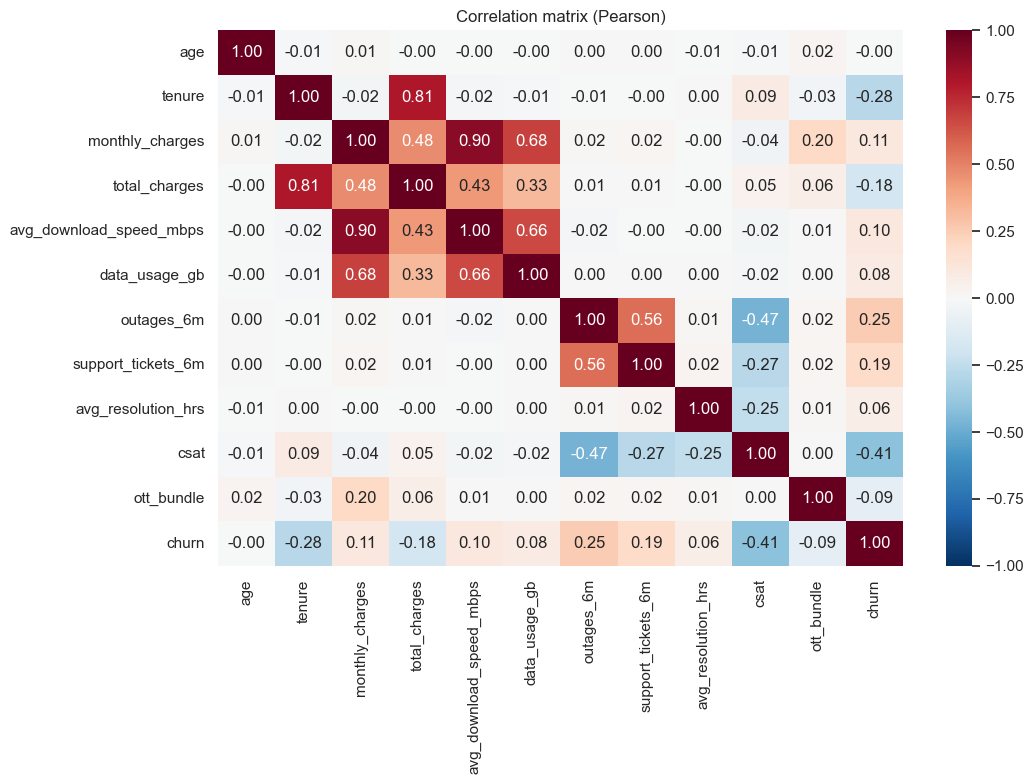

Pairs with |r| >= 0.4:
monthly_charges          avg_download_speed_mbps    0.90
tenure                   total_charges              0.81
monthly_charges          data_usage_gb              0.68
avg_download_speed_mbps  data_usage_gb              0.66
outages_6m               support_tickets_6m         0.56
monthly_charges          total_charges              0.48
outages_6m               csat                      -0.47
total_charges            avg_download_speed_mbps    0.43
csat                     churn                     -0.41
dtype: float64


In [14]:
num = ["age", "tenure", "monthly_charges", "total_charges", "avg_download_speed_mbps", "data_usage_gb",
       "outages_6m", "support_tickets_6m", "avg_resolution_hrs", "csat", "ott_bundle", "churn"]
corr = df[num].astype(float).corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix (Pearson)"); plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("Pairs with |r| >= 0.4:")
print(pairs[pairs.abs() >= 0.4].sort_values(key=abs, ascending=False).round(2))

*Interpretation:*
* **By construction — do not report:** tenure ↔ total_charges (0.81) and monthly ↔ total_charges (0.48), because
  total billed ≈ monthly charge × months. The 0.90 between monthly charges and download speed is also structural:
  the plan sets both the price and the speed.
* **Genuine relationships:** outages ↔ support tickets (0.56), outages ↔ CSAT (−0.47), CSAT ↔ churn (−0.41), and
  heavier data users pay more (0.68). The chain *outages → tickets → low CSAT → churn* is the story.

### Q14. A high-risk segment (> 60% churn) and a low-risk segment (< 15%).

In [15]:
seg = lambda mask, name: print(f"{name}: {mask.sum()} customers, churn {df.loc[mask, 'churn'].mean():.1%}")

high = (df["contract"] == "Monthly") & (df["router_type"] == "Old (ONT-v1)") & (df["tenure"] <= 12)
low = (df["contract"] == "Annual") & (df["router_type"] == "New (ONT-v3)")
seg(high, "HIGH risk: Monthly contract + old router + tenure <= 12 months")
seg(low,  "LOW risk:  Annual contract + new router")

HIGH risk: Monthly contract + old router + tenure <= 12 months: 399 customers, churn 65.9%
LOW risk:  Annual contract + new router: 1012 customers, churn 10.0%


*Interpretation:* the high-risk segment is **399 customers churning at 65.9%**; the low-risk segment is
**1,012 customers at 10.0%**. Both are large enough to act on.

# Part C — Testing the board's claims

### Test-selection table

| Q | Claim / question | Variable type(s) | Test | Why |
|---|---|---|---|---|
| 15 | Churn = 30% | 1 binary vs benchmark | one-proportion z | one sample proportion, large n |
| 16 | ARPU = ₹950, σ known | 1 numeric, σ known | one-sample z (mean) | population σ given |
| 17 | OTT churns less | binary × binary | two-proportion z (one-tailed) | compare 2 independent proportions |
| 18 | Churners low-value | numeric × 2 groups | Levene → Student/Welch t | 2 independent means, check variances |
| 19 | Upgrade improved speed | numeric, same customers twice | paired t + Wilcoxon | before/after on same people |
| 20 | Improved ≥ 10% | ratio vs 1.10 | one-sample t, one-tailed | one mean vs a fixed value |
| 21 | Churn vs contract | categorical × categorical | χ² independence + Cramér's V | two categorical variables |
| 22 | Cash/cheque leave more | categorical × categorical | χ² independence | 4 methods × churn |
| 23 | Women leave more | categorical × categorical | χ² independence | gender × churn |
| 24 | Complaint mix changed | 1 categorical vs known % | χ² goodness-of-fit | observed vs baseline proportions |
| 25 | Resolution same in every city | numeric × 5 groups | ANOVA + Levene, Tukey, Kruskal | more than 2 independent groups |
| 26 | CSAT by plan | ordinal × 4 groups | ANOVA + Kruskal-Wallis | ordinal, 4 groups |
| 27 | Churners raise more tickets | skewed count × 2 groups | Mann-Whitney U | non-normal counts |
| 28 | Outages vs CSAT; outages by router | ordinal pairs; count × 2 groups | Spearman; Mann-Whitney U | ranks, no normality needed |
| 29 | Churners shorter tenure | numeric × 2 groups | Welch t | unequal variances, large n |
| 30 | Resolution hrs normal? | 1 numeric | D'Agostino / Shapiro + Q-Q | normality check |

### Q15. Sales: "Our churn equals the 30% industry rate."

In [16]:
x, n = int(df["churn"].sum()), len(df)
z, p = proportions_ztest(x, n, value=0.30, prop_var=0.30)
lo, hi = proportion_confint(x, n, alpha=ALPHA, method="wilson")
print(f"H0: p = 0.30   H1: p != 0.30   (two-tailed)")
print(f"Assumption: n*p0 = {n*0.30:.0f} and n*(1-p0) = {n*0.70:.0f}, both >= 10 -> normal approximation OK")
print(f"Observed churn = {x/n:.4f} | z = {z:.3f}, p = {p_fmt(p)} -> {verdict(p)}")
print(f"95% CI for churn: [{lo:.4f}, {hi:.4f}] | excess over benchmark = {(x/n - 0.30)*100:.1f} pp "
      f"= {(x/n - 0.30)*n:.0f} extra customers lost")

H0: p = 0.30   H1: p != 0.30   (two-tailed)
Assumption: n*p0 = 1800 and n*(1-p0) = 4200, both >= 10 -> normal approximation OK
Observed churn = 0.3340 | z = 5.747, p = 9.081e-09 -> reject H0
95% CI for churn: [0.3222, 0.3460] | excess over benchmark = 3.4 pp = 204 extra customers lost


**(i)** H₀: p = 0.30, H₁: p ≠ 0.30 **(ii)** one-proportion z-test — one binary outcome vs a known benchmark
**(iii)** np₀ and n(1−p₀) ≫ 10 **(iv)/(v)** see output — the whole 95% CI sits above 30%.
**(vi) Business:** our churn is significantly *higher* than the industry's 30%; we are not "in line with the market".

### Q16. Marketing: "Average monthly revenue per customer is ₹950" (σ = ₹380).

In [17]:
x = df["monthly_charges"]; n = len(x); sigma = 380
se = sigma / np.sqrt(n)
z = (x.mean() - 950) / se
p = 2 * stats.norm.sf(abs(z))
zc = stats.norm.ppf(1 - ALPHA / 2)
print("H0: mu = 950   H1: mu != 950   (two-tailed)")
print(f"Assumption: n = {n} -> CLT makes the sample mean normal; sigma known = 380")
print(f"Sample mean = ₹{x.mean():.2f} | z = {z:.3f}, p = {p_fmt(p)} -> {verdict(p)}")
print(f"95% CI: [₹{x.mean() - zc*se:.2f}, ₹{x.mean() + zc*se:.2f}] | Cohen's d = {(x.mean()-950)/sigma:.3f}")

H0: mu = 950   H1: mu != 950   (two-tailed)
Assumption: n = 6000 -> CLT makes the sample mean normal; sigma known = 380
Sample mean = ₹971.01 | z = 4.282, p = 1.848e-05 -> reject H0
95% CI: [₹961.39, ₹980.62] | Cohen's d = 0.055


**(i)** H₀: μ = ₹950, H₁: μ ≠ ₹950 **(ii)** one-sample z-test — numeric mean, population σ known
**(iii)** n = 6,000, CLT applies **(iv)/(v)** see output.
**(vi) Business:** ARPU is about ₹971, not ₹950. The gap is statistically real but small (d ≈ 0.05, about ₹21 a
month) — ₹950 is a slight understatement, not a wrong picture.

### Q17. Product: "OTT-bundle customers churn less."

In [18]:
g = df.groupby("ott_bundle")["churn"].agg(["sum", "count"])
x = [g.loc[1, "sum"], g.loc[0, "sum"]]; n = [g.loc[1, "count"], g.loc[0, "count"]]
p1, p0 = x[0] / n[0], x[1] / n[1]
z, p = proportions_ztest(x, n, alternative="smaller")
se = np.sqrt(p1*(1-p1)/n[0] + p0*(1-p0)/n[1])
print("H0: p_OTT >= p_noOTT   H1: p_OTT < p_noOTT   (one-tailed)")
print(f"Assumption: every cell count >= 10: {[int(v) for v in x]}, {[int(a-b) for a, b in zip(n, x)]}")
print(f"Churn with OTT = {p1:.4f} (n={n[0]}) | without = {p0:.4f} (n={n[1]})")
print(f"z = {z:.3f}, p = {p_fmt(p)} -> {verdict(p)}")
print(f"Difference = {(p1-p0)*100:.1f} pp, 95% CI [{(p1-p0-1.96*se)*100:.1f}, {(p1-p0+1.96*se)*100:.1f}] pp | "
      f"risk ratio = {p1/p0:.2f}")

H0: p_OTT >= p_noOTT   H1: p_OTT < p_noOTT   (one-tailed)
Assumption: every cell count >= 10: [720, 1284], [1830, 2166]
Churn with OTT = 0.2824 (n=2550) | without = 0.3722 (n=3450)
z = -7.292, p = 1.522e-13 -> reject H0
Difference = -9.0 pp, 95% CI [-11.4, -6.6] pp | risk ratio = 0.76


**(i)** H₀: p_OTT ≥ p_no-OTT, H₁: p_OTT < p_no-OTT **(ii)** two-proportion z-test, one-tailed (the claim has a direction)
**(iii)** all cells ≥ 10 **(iv)/(v)** see output.
**(vi) Business:** **supported** — OTT customers churn 28.2% vs 37.2%, 9 pp lower (risk ratio 0.76). But it is an
*association*: customers who choose OTT may simply be more engaged, so "push it to everyone" needs a randomised trial.

### Q18. Marketing: "Churners are low-value customers."

In [19]:
ch = df.loc[df["churn"] == 1, "monthly_charges"]; st = df.loc[df["churn"] == 0, "monthly_charges"]
lev = stats.levene(ch, st)
equal = lev.pvalue >= ALPHA
t, p = stats.ttest_ind(ch, st, equal_var=equal)
pooled = np.sqrt(((len(ch)-1)*ch.var() + (len(st)-1)*st.var()) / (len(ch)+len(st)-2))
diff = ch.mean() - st.mean()
se = np.sqrt(ch.var()/len(ch) + st.var()/len(st))
print("H0: mu_churn = mu_stay   H1: mu_churn != mu_stay")
print(f"Levene: W = {lev.statistic:.3f}, p = {p_fmt(lev.pvalue)} -> "
      f"{'equal variances, Student t' if equal else 'unequal variances, Welch t'}")
print(f"Churners ₹{ch.mean():.2f} vs stayers ₹{st.mean():.2f} | t = {t:.3f}, p = {p_fmt(p)} -> {verdict(p)}")
print(f"Difference = ₹{diff:.2f}, 95% CI [₹{diff-1.96*se:.2f}, ₹{diff+1.96*se:.2f}] | Cohen's d = {diff/pooled:.3f}")
print("Basic-plan share: churners", f"{(df.loc[df.churn==1,'plan_type']=='Basic 50 Mbps').mean():.1%}",
      "| stayers", f"{(df.loc[df.churn==0,'plan_type']=='Basic 50 Mbps').mean():.1%}")

H0: mu_churn = mu_stay   H1: mu_churn != mu_stay
Levene: W = 54.432, p = 1.827e-13 -> unequal variances, Welch t
Churners ₹1028.16 vs stayers ₹942.35 | t = 7.822, p = 6.8e-15 -> reject H0
Difference = ₹85.81, 95% CI [₹64.31, ₹107.31] | Cohen's d = 0.224
Basic-plan share: churners 25.0% | stayers 32.8%


**(i)** H₀: equal mean charges, H₁: different **(ii)** independent two-sample t — numeric, two independent groups
**(iii)** Levene decides Student vs Welch **(iv)/(v)** see output.
Levene rejects equal variances, so **Welch's t** is used.
**(vi) Business:** **rejected — the opposite is true.** Churners pay ₹86 *more* per month (₹1,028 vs ₹942, small
effect d = 0.22), and only 25% of churners are on Basic vs 33% of stayers. We are losing our higher-value customers.

### Q19. Network: "The router upgrade improved speeds" — paired, 180 pilot customers.

n = 180 pilot customers (all in Pune)
H0: mean(Oct - Jun) <= 0   H1: mean(Oct - Jun) > 0   (one-tailed, paired)
Shapiro on differences: W = 0.6317, p = 1.634e-19 -> not normal -> rely on Wilcoxon as confirmation
Paired t = 6.055, p = 4.027e-09 -> reject H0
Wilcoxon signed-rank: W = 14085, p = 1.076e-17 -> reject H0
Mean gain = 9.74 Mbps, 95% CI [6.57, 12.91] | median gain = 5.30 | d_z = 0.451 | improved: 79% of customers


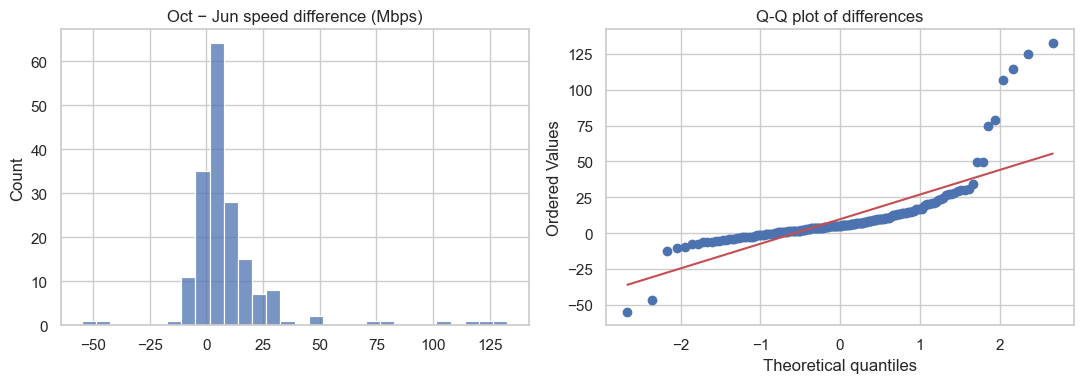

In [20]:
pilot = df[df["pilot_group"] == "Yes"].dropna(subset=["speed_test_jun", "speed_test_oct"])
jun, octo = pilot["speed_test_jun"], pilot["speed_test_oct"]
diff = octo - jun
sh = stats.shapiro(diff)
t, p = stats.ttest_rel(octo, jun, alternative="greater")
w = stats.wilcoxon(octo, jun, alternative="greater")
ci = stats.t.interval(0.95, len(diff)-1, loc=diff.mean(), scale=stats.sem(diff))
print(f"n = {len(pilot)} pilot customers (all in Pune)")
print("H0: mean(Oct - Jun) <= 0   H1: mean(Oct - Jun) > 0   (one-tailed, paired)")
print(f"Shapiro on differences: W = {sh.statistic:.4f}, p = {p_fmt(sh.pvalue)} -> "
      f"{'normal' if sh.pvalue >= ALPHA else 'not normal -> rely on Wilcoxon as confirmation'}")
print(f"Paired t = {t:.3f}, p = {p_fmt(p)} -> {verdict(p)}")
print(f"Wilcoxon signed-rank: W = {w.statistic:.0f}, p = {p_fmt(w.pvalue)} -> {verdict(w.pvalue)}")
print(f"Mean gain = {diff.mean():.2f} Mbps, 95% CI [{ci[0]:.2f}, {ci[1]:.2f}] | median gain = {diff.median():.2f} | "
      f"d_z = {diff.mean()/diff.std():.3f} | improved: {(diff > 0).mean():.0%} of customers")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(diff, bins=30, ax=ax[0]); ax[0].set_title("Oct − Jun speed difference (Mbps)")
stats.probplot(diff, plot=ax[1]); ax[1].set_title("Q-Q plot of differences")
plt.tight_layout(); plt.show()

**(i)** H₀: mean change ≤ 0, H₁: mean change > 0 **(ii)** paired t — the *same* 180 customers measured twice, so
the groups are not independent **(iii)** Shapiro on the differences; Wilcoxon signed-rank as the non-parametric check
**(iv)/(v)** see output.
The differences are not normal (Shapiro p ≈ 0), so the Wilcoxon signed-rank test is the deciding check — and it agrees.
**(vi) Business:** **supported** — speeds rose by 9.7 Mbps on average (median 5.3) and 79% of pilot customers improved.
See Q20 for *how much*, and Q32: with no control group, part of the gain could be seasonal or network-wide.

### Q20. Network: "…by at least 10%."

In [21]:
ratio = octo / jun
t, p = stats.ttest_1samp(ratio, 1.10, alternative="less")
ci = stats.t.interval(0.95, len(ratio)-1, loc=ratio.mean(), scale=stats.sem(ratio))
print("H0: mean ratio >= 1.10   H1: mean ratio < 1.10   (one-tailed)")
print(f"Shapiro on ratio: p = {p_fmt(stats.shapiro(ratio).pvalue)} (n = {len(ratio)}, CLT applies)")
print(f"Mean Oct/Jun ratio = {ratio.mean():.4f} (= {(ratio.mean()-1)*100:.1f}% gain) | t = {t:.3f}, p = {p_fmt(p)} -> {verdict(p)}")
print(f"95% CI for ratio: [{ci[0]:.4f}, {ci[1]:.4f}] | customers with >= 10% gain: {(ratio >= 1.10).mean():.0%}")

H0: mean ratio >= 1.10   H1: mean ratio < 1.10   (one-tailed)
Shapiro on ratio: p = 0.2075 (n = 180, CLT applies)
Mean Oct/Jun ratio = 1.0704 (= 7.0% gain) | t = -4.499, p = 6.135e-06 -> reject H0
95% CI for ratio: [1.0574, 1.0834] | customers with >= 10% gain: 36%


**(i)** H₀: mean ratio ≥ 1.10 (the claim), H₁: mean ratio < 1.10 **(ii)** one-sample t, one-tailed — one numeric
mean vs a fixed value **(iii)** n = 180, CLT **(iv)/(v)** see output.
**(vi) Business:** **rejected** — the average gain is **7.0%** (95% CI 5.7%–8.3%), significantly below 10%, and only
36% of customers got 10% or more. The upgrade helps, but the "at least 10%" promise is not supported.

### Q21. Is churn independent of contract type?

In [22]:
ct = pd.crosstab(df["contract"], df["churn"])
chi2, p, dof, exp = stats.chi2_contingency(ct)
v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print("H0: churn is independent of contract type   H1: they are associated")
print(ct.assign(churn_rate=(ct[1] / ct.sum(axis=1)).round(4)))
print(f"Expected counts: min = {exp.min():.1f}, all >= 5: {(exp >= 5).all()}")
print(f"chi2 = {chi2:.3f}, dof = {dof}, p = {p_fmt(p)} -> {verdict(p)} | Cramér's V = {v:.3f}")

H0: churn is independent of contract type   H1: they are associated
churn         0     1  churn_rate
contract                         
Annual     1372   225      0.1409
Monthly    1614  1439      0.4713
Quarterly  1010   340      0.2519
Expected counts: min = 450.9, all >= 5: True
chi2 = 567.565, dof = 2, p = 5.686e-124 -> reject H0 | Cramér's V = 0.308


**(i)** H₀: independent, H₁: associated **(ii)** χ² test of independence — two categorical variables
**(iii)** all expected counts ≥ 5 **(iv)/(v)** see output; Cramér's V ≈ 0.1 small, 0.3 medium, 0.5 large.
**(vi) Business:** churn depends strongly on contract (V = 0.31, a medium effect — the largest in this data):
Monthly 47% vs Quarterly 25% vs Annual 14%. Moving customers to longer contracts is the biggest lever.

### Q22. Finance: "Cash/cheque customers leave more."

In [23]:
ct = pd.crosstab(df["payment_method"], df["churn"])
chi2, p, dof, exp = stats.chi2_contingency(ct)
v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print("H0: churn is independent of payment method   H1: they are associated")
print(ct.assign(churn_rate=(ct[1] / ct.sum(axis=1)).round(4)))
print(f"Expected counts: min = {exp.min():.1f}, all >= 5: {(exp >= 5).all()}")
print(f"chi2 = {chi2:.3f}, dof = {dof}, p = {p_fmt(p)} -> {verdict(p)} | Cramér's V = {v:.3f}")

H0: churn is independent of payment method   H1: they are associated
churn              0    1  churn_rate
payment_method                       
Cash/Cheque      580  431      0.4263
Credit Card      837  432      0.3404
Net Banking      814  359      0.3061
UPI AutoPay     1765  782      0.3070
Expected counts: min = 337.7, all >= 5: True
chi2 = 51.413, dof = 3, p = 3.995e-11 -> reject H0 | Cramér's V = 0.093


**(i)** H₀: independent, H₁: associated **(ii)** χ² independence (4 payment methods × churn)
**(iii)** expected counts ≥ 5 **(iv)/(v)** see output and the churn_rate column.
**(vi) Business:** **supported** — Cash/Cheque customers churn 42.6% vs about 31% for the other methods. The effect
is small (V = 0.09) but real; moving them to UPI AutoPay removes the monthly "should I renew?" moment.

### Q23. HR: "Women leave more."

In [24]:
ct = pd.crosstab(df["gender"], df["churn"])
chi2, p, dof, exp = stats.chi2_contingency(ct)
v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print("H0: churn is independent of gender   H1: they are associated")
print(ct.assign(churn_rate=(ct[1] / ct.sum(axis=1)).round(4)))
print(f"Expected counts: min = {exp.min():.1f}, all >= 5: {(exp >= 5).all()}")
print(f"chi2 = {chi2:.3f}, dof = {dof}, p = {p_fmt(p)} -> {verdict(p)} | Cramér's V = {v:.3f}")

H0: churn is independent of gender   H1: they are associated
churn      0     1  churn_rate
gender                        
Female  1746   878      0.3346
Male    2250  1126      0.3335
Expected counts: min = 876.4, all >= 5: True
chi2 = 0.004, dof = 1, p = 0.9523 -> fail to reject H0 | Cramér's V = 0.001


**(i)** H₀: independent, H₁: associated **(ii)** χ² independence (2 × 2) **(iii)** expected counts ≥ 5
**(iv)/(v)** see output.
**(vi) Business / interpretation of a non-significant result:** p = 0.95, so we **fail to reject H₀** — women 33.5%,
men 33.4%. The data show *no evidence* that women leave more. That is not proof that churn is identical: it means any gender gap is too
small to detect even with 6,000 customers (Cramér's V ≈ 0), so it is not worth acting on.

### Q24. Has the complaint mix changed from last year's baseline?

In [25]:
baseline = {"Slow speed": .20, "Frequent disconnection": .20, "Billing dispute": .15,
            "Installation delay": .10, "Router fault": .10, "None": .25}
obs = df.loc[df["last_complaint_category"] != "Unknown", "last_complaint_category"].value_counts()
obs = obs.reindex(baseline.keys())
expected = pd.Series(baseline) * obs.sum()
chi2, p = stats.chisquare(obs, expected)
resid = (obs - expected) / np.sqrt(expected)
print("H0: complaint mix = FY2025 baseline   H1: mix has changed")
print(f"n = {obs.sum()} (Unknown excluded) | min expected = {expected.min():.1f}")
print(f"chi2 = {chi2:.3f}, dof = {len(obs)-1}, p = {p_fmt(p)} -> {verdict(p)} | "
      f"Cohen's w = {np.sqrt(chi2/obs.sum()):.3f}")
print(pd.DataFrame({"observed": obs, "expected": expected.round(0), "observed %": (obs/obs.sum()*100).round(1),
                    "baseline %": pd.Series(baseline)*100, "std residual": resid.round(2)}))

H0: complaint mix = FY2025 baseline   H1: mix has changed
n = 5906 (Unknown excluded) | min expected = 590.6
chi2 = 216.526, dof = 5, p = 8.241e-45 -> reject H0 | Cohen's w = 0.191
                        observed  expected  observed %  baseline %  std residual
Slow speed                  1393    1181.0        23.6        20.0          6.16
Frequent disconnection      1296    1181.0        21.9        20.0          3.34
Billing dispute              810     886.0        13.7        15.0         -2.55
Installation delay           364     591.0         6.2        10.0         -9.32
Router fault                 760     591.0        12.9        10.0          6.97
None                        1283    1476.0        21.7        25.0         -5.04


**(i)** H₀: the mix equals the baseline, H₁: it has changed **(ii)** χ² goodness-of-fit — one categorical variable
vs known proportions **(iii)** all expected counts ≥ 5 **(iv)/(v)** see output.
Categories with |standardised residual| > 2 drove the change: **Router fault** (+7.0, 10% → 12.9%), **Slow speed**
(+6.2, 20% → 23.6%) and **Frequent disconnection** (+3.3) grew; **Installation delay** (−9.3, 10% → 6.2%) and
**None** (−5.0) shrank.
**(vi) Business:** the mix has shifted (small-to-medium effect, w = 0.19) toward **network and router problems**,
while installation complaints fell — the pain has moved from getting connected to staying connected.

### Q25. Customer Service: "Resolution time is the same in every city."

In [26]:
groups = [g["avg_resolution_hrs"].values for _, g in df.groupby("city")]
print("H0: mean resolution hours equal in all 5 cities   H1: at least one differs")
print(df.groupby("city")["avg_resolution_hrs"].agg(["count", "mean", "median", "std"]).round(2))
lev = stats.levene(*groups)
print(f"Levene: W = {lev.statistic:.3f}, p = {p_fmt(lev.pvalue)}"
      f" -> {'equal variances' if lev.pvalue >= ALPHA else 'unequal variances (Welch/Kruskal as backup)'}")
f, p = stats.f_oneway(*groups)
ss_between = sum(len(g) * (g.mean() - df["avg_resolution_hrs"].mean())**2 for g in groups)
ss_total = ((df["avg_resolution_hrs"] - df["avg_resolution_hrs"].mean())**2).sum()
print(f"One-way ANOVA: F = {f:.3f}, p = {p_fmt(p)} -> {verdict(p)} | eta² = {ss_between/ss_total:.4f}")
k = stats.kruskal(*groups)
print(f"Kruskal-Wallis: H = {k.statistic:.3f}, p = {p_fmt(k.pvalue)} -> {verdict(k.pvalue)}")
print(pairwise_tukeyhsd(df["avg_resolution_hrs"], df["city"], alpha=ALPHA))

H0: mean resolution hours equal in all 5 cities   H1: at least one differs
            count   mean  median    std
city                                   
Aurangabad    756  23.58   20.80  12.72
Mumbai       1668  16.10   15.10   7.99
Nagpur        890  27.33   25.45  12.95
Nashik        943  19.67   17.70  10.00
Pune         1743  17.97   17.10   8.80
Levene: W = 74.004, p = 2.569e-61 -> unequal variances (Welch/Kruskal as backup)
One-way ANOVA: F = 222.283, p = 3.621e-178 -> reject H0 | eta² = 0.1292
Kruskal-Wallis: H = 681.589, p = 3.377e-146 -> reject H0


   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1   group2 meandiff p-adj   lower    upper  reject
---------------------------------------------------------
Aurangabad Mumbai  -7.4809    0.0  -8.6844 -6.2774   True
Aurangabad Nagpur   3.7541    0.0   2.3964  5.1119   True
Aurangabad Nashik  -3.9037    0.0  -5.2438 -2.5636   True
Aurangabad   Pune  -5.6055    0.0  -6.8009   -4.41   True
    Mumbai Nagpur   11.235    0.0  10.0956 12.3745   True
    Mumbai Nashik   3.5772    0.0   2.4588  4.6956   True
    Mumbai   Pune   1.8754    0.0   0.9352  2.8157   True
    Nagpur Nashik  -7.6578    0.0  -8.9407  -6.375   True
    Nagpur   Pune  -9.3596    0.0 -10.4905 -8.2287   True
    Nashik   Pune  -1.7018 0.0003  -2.8115 -0.5921   True
---------------------------------------------------------


**(i)** H₀: μ equal in all cities, H₁: at least one differs **(ii)** one-way ANOVA — numeric outcome, 5 independent
groups **(iii)** Levene for equal variances; resolution hours are skewed (Q12) so Kruskal-Wallis confirms
**(iv)/(v)** see output; η² = share of variance explained by city; Tukey HSD shows *which* cities differ.
Levene rejects equal variances, so ANOVA alone is not trusted — Kruskal-Wallis (rank-based) confirms the result.
**(vi) Business:** **rejected** — Nagpur takes 27.3 hrs on average and Aurangabad 23.6, against 16.1 in Mumbai. City
explains 13% of the variation (η² = 0.13, a medium-large effect) and Tukey finds every pair of cities different.
Nagpur and Aurangabad service teams are the place to start.

### Q26. Does CSAT differ across plan types? Is it practically significant?

In [27]:
cs = df.astype({"csat": float})
groups = [g["csat"].values for _, g in cs.groupby("plan_type")]
print("H0: CSAT distribution is the same on every plan   H1: at least one plan differs")
print(cs.groupby("plan_type")["csat"].agg(["count", "mean", "median"]).round(3))
print(f"Levene p = {p_fmt(stats.levene(*groups).pvalue)}")
f, p = stats.f_oneway(*groups)
eta = sum(len(g)*(g.mean()-cs['csat'].mean())**2 for g in groups) / ((cs['csat']-cs['csat'].mean())**2).sum()
k = stats.kruskal(*groups)
eps = (k.statistic - len(groups) + 1) / (len(cs) - len(groups))
print(f"ANOVA: F = {f:.3f}, p = {p_fmt(p)} -> {verdict(p)} | eta² = {eta:.4f}")
print(f"Kruskal-Wallis: H = {k.statistic:.3f}, p = {p_fmt(k.pvalue)} -> {verdict(k.pvalue)} | epsilon² = {eps:.4f}")

H0: CSAT distribution is the same on every plan   H1: at least one plan differs
                   count   mean  median
plan_type                              
Basic 50 Mbps       1812  3.628     4.0
Premium 300 Mbps    1302  3.565     4.0
Standard 100 Mbps   2238  3.584     4.0
Ultra 1 Gbps         648  3.485     4.0
Levene p = 0.06516
ANOVA: F = 4.209, p = 0.005545 -> reject H0 | eta² = 0.0021
Kruskal-Wallis: H = 14.235, p = 0.002602 -> reject H0 | epsilon² = 0.0019


**(i)** H₀: same CSAT across plans, H₁: at least one differs **(ii)** CSAT is ordinal (1–5), so Kruskal-Wallis is
the primary test with ANOVA alongside **(iii)** Levene; ordinal data → rank test **(iv)/(v)** see output.
**Practical significance:** p = 0.003 is "significant", but η² = 0.002 — plan explains **0.2%** of CSAT variation.
The means run from 3.49 (Ultra) to 3.63 (Basic) and every plan's median is 4. A textbook case of significant but
too small to matter at n = 6,000.
**(vi) Business:** satisfaction does not meaningfully depend on which plan a customer is on.

### Q27. Do churners raise more support tickets?

In [28]:
ch = df.loc[df["churn"] == 1, "support_tickets_6m"]; st = df.loc[df["churn"] == 0, "support_tickets_6m"]
u, p = stats.mannwhitneyu(ch, st, alternative="greater")
rbc = 2 * u / (len(ch) * len(st)) - 1
print("H0: churners' tickets are not stochastically greater   H1: churners raise more tickets (one-tailed)")
print(f"Skew = {df['support_tickets_6m'].skew():.2f}, D'Agostino p = {p_fmt(stats.normaltest(df['support_tickets_6m']).pvalue)} -> non-normal counts")
print(f"Median tickets: churners {ch.median()} vs stayers {st.median()} | means {ch.mean():.2f} vs {st.mean():.2f}")
print(f"Mann-Whitney U = {u:.0f}, p = {p_fmt(p)} -> {verdict(p)} | rank-biserial r = {rbc:.3f}")

H0: churners' tickets are not stochastically greater   H1: churners raise more tickets (one-tailed)
Skew = 1.19, D'Agostino p = 5.716e-253 -> non-normal counts
Median tickets: churners 2.0 vs stayers 1.0 | means 2.20 vs 1.56
Mann-Whitney U = 4852330, p = 2.787e-43 -> reject H0 | rank-biserial r = 0.212


**(i)** H₀: no shift, H₁: churners higher **(ii)** Mann-Whitney U — skewed count data, two independent groups
**(iii)** normality fails, so a rank test is used **(iv)/(v)** see output; rank-biserial r ≈ 0.1 small, 0.3 medium,
0.5 large.
**(vi) Business:** yes — churners' median is 2 tickets vs 1 for stayers (rank-biserial r = 0.21, a small-to-medium
effect). Repeated support calls are an early-warning flag for churn.

### Q28. Are outages related to CSAT? Are outages higher on old routers?

In [29]:
rho, p = stats.spearmanr(df["outages_6m"], df["csat"].astype(float))
print("(a) H0: rho = 0 (no monotonic relation)   H1: rho != 0")
print(f"Spearman rho = {rho:.3f}, p = {p_fmt(p)} -> {verdict(p)}")

old = df.loc[df["router_type"] == "Old (ONT-v1)", "outages_6m"]
new = df.loc[df["router_type"] == "New (ONT-v3)", "outages_6m"]
u, p2 = stats.mannwhitneyu(old, new, alternative="greater")
rbc = 2 * u / (len(old) * len(new)) - 1
print("\n(b) H0: old-router outages not higher   H1: old routers have more outages (one-tailed)")
print(f"Median outages old {old.median()} vs new {new.median()} | means {old.mean():.2f} vs {new.mean():.2f}")
print(f"Mann-Whitney U = {u:.0f}, p = {p_fmt(p2)} -> {verdict(p2)} | rank-biserial r = {rbc:.3f}")

(a) H0: rho = 0 (no monotonic relation)   H1: rho != 0
Spearman rho = -0.439, p = 2.295e-281 -> reject H0

(b) H0: old-router outages not higher   H1: old routers have more outages (one-tailed)
Median outages old 3.0 vs new 1.0 | means 3.19 vs 1.58
Mann-Whitney U = 6395612, p = 3.156e-274 -> reject H0 | rank-biserial r = 0.538


**(i)** (a) H₀: ρ = 0; (b) H₀: old ≤ new **(ii)** Spearman — both variables are ordinal/count, no normality needed;
Mann-Whitney — skewed counts, two groups **(iii)** rank-based, assumption-light **(iv)/(v)** see output.
**(vi) Business:** (a) more outages go with lower CSAT (ρ = −0.44, moderate); (b) old ONT-v1 routers have about
**twice** the outages (mean 3.2 vs 1.6, r = 0.54, a large effect). Old routers → outages → unhappy customers.

### Q29. Do churners have shorter tenure?

In [30]:
ch = df.loc[df["churn"] == 1, "tenure"]; st = df.loc[df["churn"] == 0, "tenure"]
lev = stats.levene(ch, st)
t, p = stats.ttest_ind(ch, st, equal_var=False, alternative="less")
diff = ch.mean() - st.mean(); se = np.sqrt(ch.var()/len(ch) + st.var()/len(st))
pooled = np.sqrt((ch.var() + st.var()) / 2)
print("H0: mu_churn >= mu_stay   H1: churners have shorter tenure (one-tailed)")
print(f"Levene p = {p_fmt(lev.pvalue)} -> Welch's t (does not assume equal variances)")
print(f"Mean tenure: churners {ch.mean():.1f} vs stayers {st.mean():.1f} months")
print(f"Welch t = {t:.3f}, p = {p_fmt(p)} -> {verdict(p)}")
print(f"Difference = {diff:.1f} months, 95% CI [{diff-1.96*se:.1f}, {diff+1.96*se:.1f}] | Cohen's d = {diff/pooled:.3f}")

H0: mu_churn >= mu_stay   H1: churners have shorter tenure (one-tailed)
Levene p = 1.289e-43 -> Welch's t (does not assume equal variances)
Mean tenure: churners 18.7 vs stayers 28.3 months
Welch t = -24.672, p = 1.692e-127 -> reject H0
Difference = -9.6 months, 95% CI [-10.4, -8.8] | Cohen's d = -0.641


**(i)** H₀: churners' tenure ≥ stayers', H₁: shorter **(ii)** Welch's t — numeric, two independent groups, unequal
variances **(iii)** Levene; n large so CLT covers the skew **(iv)/(v)** see output.
**(vi) Business:** yes — churners stayed 18.7 months on average vs 28.3 for stayers, 9.6 months shorter (d = 0.64,
a medium effect). Early life and the first renewals are where customers are lost.

### Q30. Is avg_resolution_hrs normally distributed? Does a log transform help?

raw: skew = 1.400 | D'Agostino K2 = 1611.7, p = 0 | Shapiro (random n=500) p = 5.474e-16
log: skew = -0.372 | D'Agostino K2 = 157.2, p = 7.278e-35 | Shapiro (random n=500) p = 5.172e-05


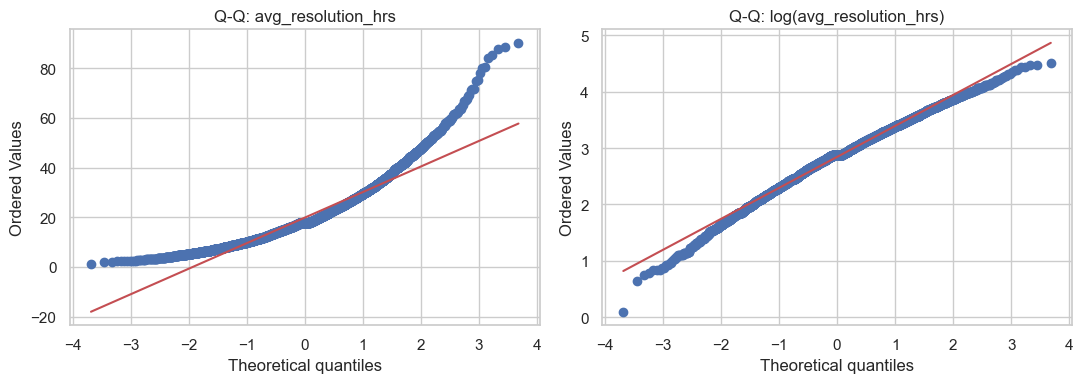

In [31]:
r = df["avg_resolution_hrs"]; lr = np.log(r)
for name, s in [("raw", r), ("log", lr)]:
    k2, p = stats.normaltest(s)
    sw = stats.shapiro(s.sample(500, random_state=1))
    print(f"{name:3}: skew = {s.skew():.3f} | D'Agostino K2 = {k2:.1f}, p = {p_fmt(p)} | "
          f"Shapiro (random n=500) p = {p_fmt(sw.pvalue)}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
stats.probplot(r, plot=ax[0]); ax[0].set_title("Q-Q: avg_resolution_hrs")
stats.probplot(lr, plot=ax[1]); ax[1].set_title("Q-Q: log(avg_resolution_hrs)")
plt.tight_layout(); plt.show()

**Answer:** raw resolution hours are not normal (skew 1.40, curved Q-Q plot, p ≈ 0). The log transform cuts the skew
to −0.37 and straightens most of the Q-Q plot, so it **helps a lot** — but the tests still reject (p < 0.001).
**Sample size:** at n ≈ 6,000 a normality test has so much power that it rejects even trivial departures from
normality, so with large samples look at the Q-Q plot and skewness rather than the p-value — and remember the CLT
makes t-tests on *means* valid anyway.

# Part D — Recommendation to the CEO

### Q31. Rupee value of a 5-percentage-point drop in churn.

In [32]:
customers = len(df)
saved = 0.05 * customers
arpu = df["monthly_charges"].mean()
replacement = saved * 2400
revenue = saved * arpu * 12
print(f"5 pp of {customers} customers = {saved:.0f} customers kept per year")
print(f"Replacement cost avoided: {saved:.0f} x ₹2,400 = ₹{replacement:,.0f}")
print(f"Monthly revenue retained: {saved:.0f} x ₹{arpu:.0f} x 12 = ₹{revenue:,.0f}")
print(f"Total value per year: ₹{replacement + revenue:,.0f}  (≈ ₹{(replacement + revenue)/1e5:.1f} lakh)")

5 pp of 6000 customers = 300 customers kept per year
Replacement cost avoided: 300 x ₹2,400 = ₹720,000
Monthly revenue retained: 300 x ₹971 x 12 = ₹3,495,632
Total value per year: ₹4,215,632  (≈ ₹42.2 lakh)


**Assumptions:** customer base stays ~6,000; each retained customer would otherwise have been replaced at ₹2,400; a
retained customer pays the average ₹971 for a full year (an upper bound — the revenue part is roughly halved if they
would have left mid-year on average).

#### Verdict on the board's claims (full memo: **CEO_memo.pdf**)

| Claim | Verdict | Evidence |
|---|---|---|
| Sales: churn = 30% industry | **Rejected** | 33.4% (CI 32.2–34.6%), 204 more customers lost than the benchmark |
| Marketing: ARPU = ₹950 | **Rejected, but trivial** | ₹971 (CI ₹961–₹981); d = 0.05 |
| Marketing: churners are low-value | **Rejected — opposite** | churners pay ₹1,028 vs ₹942; Ultra churns 47% |
| Product: OTT keeps people | **Supported (association)** | 28.2% vs 37.2% churn |
| Network: upgrade improved speed | **Supported** | +9.7 Mbps, 79% improved (Wilcoxon p ≈ 1e-17) |
| Network: by at least 10% | **Rejected** | mean gain 7.0% (CI 5.7–8.3%) |
| Customer Service: resolution same everywhere | **Rejected** | Nagpur 27.3 h vs Mumbai 16.1 h, η² = 0.13 |
| HR: women leave more | **No evidence** | 33.5% vs 33.4%, p = 0.95 |
| Finance: cash/cheque leave more | **Supported (small)** | 42.6% vs ~31%, V = 0.09 |

**Top three levers:** (1) move Monthly customers to Quarterly/Annual contracts — 47% vs 14% churn;
(2) replace ONT-v1 routers — 43% vs 28% churn and twice the outages; (3) fix service in Nagpur and Aurangabad and
flag customers with repeated tickets / outages in their first year.

### Q32. Two things this data cannot tell us — and what to ask for next

1. **Causation.** Every result in Part C is an association. OTT customers churn less, but they *chose* OTT — they may
   be more engaged anyway. **Ask for:** a randomised retention test — offer OTT (or a contract upgrade) to a random half
   of at-risk monthly customers and compare churn after 6 months.
2. **The router pilot had no control group.** Speeds rose between June and October for the 180 Pune customers, but
   we cannot separate the upgrade from network-wide changes or seasonality (monsoon in June). The pilot was also
   Pune-only. **Ask for:** June/October speed tests for comparable *non-upgraded* Pune customers (difference-in-differences),
   and a pilot in a second city.
3. **"Significant" is easy at n ≈ 6,000.** ARPU ₹971 vs ₹950 is "significant" yet only ₹21. **Ask for:** the
   business threshold that matters (e.g. "a ₹50 ARPU gap changes pricing") so effects are judged on size, not p.
4. **Snapshot, not history.** We see one row per customer at 31 Oct 2026, not *when* outages and tickets happened
   relative to the churn date. **Ask for:** monthly event logs per customer so we can model time-to-churn.